In [10]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix
import matplotlib.pyplot as plt
import time

In [11]:
df=pd.read_csv("/home/backup/ml_datasets/mnist.csv")
print(df)
print(df.info())
print(df.isnull().sum())
print(df.shape)

       pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  pixel9  \
0         0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
1         0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
2         0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
3         0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
4         0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
...       ...     ...     ...     ...     ...     ...     ...     ...     ...   
69995     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
69996     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
69997     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
69998     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
69999     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   

       pixel10  ...  pixel7

In [12]:
x=df.drop('class',axis=1)
x=x[:20000]
print(x)
y=df['class']
y=y[:20000]
print(y)

       pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  pixel9  \
0         0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
1         0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
2         0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
3         0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
4         0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
...       ...     ...     ...     ...     ...     ...     ...     ...     ...   
19995     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
19996     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
19997     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
19998     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   
19999     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0     0.0   

       pixel10  ...  pixel7

In [13]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print("Splitted")
training_time=[]

Splitted


In [14]:
sig_model=MLPClassifier(
    hidden_layer_sizes=(128,64),
    activation="logistic",
    solver="adam",
    max_iter=1000,
    random_state=42
)
start_time_sig=time.time()
sig_model.fit(x_train[:5000],y_train[:5000])
training_time_sig=time.time()-start_time_sig
training_time.append(training_time_sig)

In [15]:
sig_pred=sig_model.predict(x_test[:2000])
print("Sigmoid Activation\n\n")
print("Accuracy: ",accuracy_score(y_test[:2000],sig_pred))
print("Precisiopn: ",precision_score(y_test[:2000],sig_pred,average='macro'))
print("Recall: ",recall_score(y_test[:2000],sig_pred,average='macro'))
print("F1 Score: ",f1_score(y_test[:2000],sig_pred,average='macro'))
print("\n\nConfusiion matrix\n",confusion_matrix(y_test[:2000],sig_pred))
print("\n\nClassification report\n\n",classification_report(y_test[:2000],sig_pred))

Sigmoid Activation


Accuracy:  0.927
Precisiopn:  0.9263340934495912
Recall:  0.926455870109568
F1 Score:  0.9262597528971321


Confusiion matrix
 [[183   0   1   0   0   1   2   0   0   1]
 [  0 232   2   2   0   2   0   0   4   1]
 [  2   1 168   3   2   1   2   4   2   0]
 [  1   0   2 192   0   4   0   0   4   1]
 [  0   2   1   0 178   0   2   2   1  12]
 [  4   1   0   2   1 153   2   0   4   2]
 [  0   0   1   0   3   2 187   0   1   0]
 [  0   0   1   2   3   0   0 197   0   3]
 [  2   5   5   4   1   1   5   0 179   3]
 [  4   0   0   3   6   1   1   4   4 185]]


Classification report

               precision    recall  f1-score   support

           0       0.93      0.97      0.95       188
           1       0.96      0.95      0.96       243
           2       0.93      0.91      0.92       185
           3       0.92      0.94      0.93       204
           4       0.92      0.90      0.91       198
           5       0.93      0.91      0.92       169
           6    

In [16]:
relu_model=MLPClassifier(
    hidden_layer_sizes=(128,64),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42
)
start_time_relu=time.time()
relu_model.fit(x_train[:5000],y_train[:5000])
training_time_relu=time.time()-start_time_relu
training_time.append(training_time_relu)


In [17]:
relu_pred=relu_model.predict(x_test[:2000])
y_test=y_test[:2000]
print("ReLU Activation\n\n")
print("Accuracy: ",accuracy_score(y_test,relu_pred))
print("Precision: ",precision_score(y_test,relu_pred,average='macro'))
print("Recall: ",recall_score(y_test,relu_pred,average='macro'))
print("F1 Score: ",f1_score(y_test,relu_pred,average='macro'))
print("Confusion Matrix\n\n",confusion_matrix(y_test,relu_pred))
print("\n\nClassification Report\n\n",classification_report(y_test,relu_pred))

ReLU Activation


Accuracy:  0.885
Precision:  0.8834596819359313
Recall:  0.882929923908941
F1 Score:  0.8828744690240431
Confusion Matrix

 [[173   1   1   1   0   4   4   0   1   3]
 [  0 232   4   0   3   0   1   2   1   0]
 [  3   2 158   7   5   0   2   3   4   1]
 [  6   2   3 174   1  11   0   1   4   2]
 [  0   0   0   1 172   0   4   3   5  13]
 [  1   0   1   7   1 140   7   1   7   4]
 [  0   2   3   0   1   3 183   0   2   0]
 [  1   0   2   2   8   0   1 183   0   9]
 [  2   3   9   4   1   6   5   1 169   5]
 [  1   0   2   2   9   1   0   5   2 186]]


Classification Report

               precision    recall  f1-score   support

           0       0.93      0.92      0.92       188
           1       0.96      0.95      0.96       243
           2       0.86      0.85      0.86       185
           3       0.88      0.85      0.87       204
           4       0.86      0.87      0.86       198
           5       0.85      0.83      0.84       169
           6       0.8

In [19]:
tanh_model=MLPClassifier(
    hidden_layer_sizes=(128,64),
    activation="tanh",
    solver="adam",
    max_iter=1000
)
start_time_tanh=time.time()
tanh_model.fit(x_train[:5000],y_train[:5000])
training_time_tanh=time.time()-start_time_tanh
training_time.append(training_time_tanh)

In [20]:
tanh_pred=tanh_model.predict(x_test[:2000])
y_test=y_test[:2000]
print("Tanh Activation\n\n")
print("Accuracy: ",accuracy_score(y_test,tanh_pred))
print("Precision: ",precision_score(y_test,tanh_pred,average='macro'))
print("Recall: ",recall_score(y_test,tanh_pred,average='macro'))
print("F1 Score: ",f1_score(y_test,tanh_pred,average='macro'))
print("\nConfusion Matrix\n\n",confusion_matrix(y_test,tanh_pred))
print("\nClassification Report\n\n",classification_report(y_test,tanh_pred))

Tanh Activation


Accuracy:  0.892
Precision:  0.890722362850483
Recall:  0.8902466787257988
F1 Score:  0.8894861679210541

Confusion Matrix

 [[178   0   0   3   2   0   2   0   2   1]
 [  0 234   2   1   2   1   2   0   1   0]
 [  1   1 168   4   2   1   3   2   3   0]
 [  3   1   3 184   0   4   0   4   3   2]
 [  0   2   0   0 176   3   3   1   1  12]
 [  5   2   1  10   0 137   4   3   4   3]
 [  0   1   1   0   1   4 186   0   1   0]
 [  3   0   5   1   2   0   0 189   1   5]
 [  2   8   7  12   5   8   5   1 152   5]
 [  2   0   1   2  12   1   0   8   2 180]]

Classification Report

               precision    recall  f1-score   support

           0       0.92      0.95      0.93       188
           1       0.94      0.96      0.95       243
           2       0.89      0.91      0.90       185
           3       0.85      0.90      0.87       204
           4       0.87      0.89      0.88       198
           5       0.86      0.81      0.84       169
           6       0.9

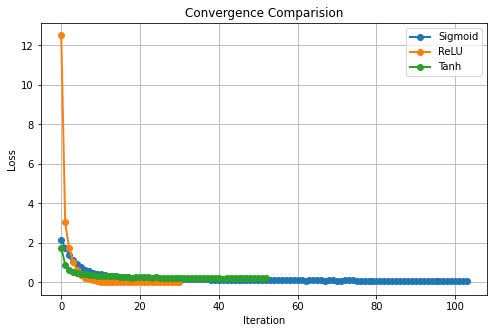

In [21]:
loss_curves={}
loss_curves["logistic"]=sig_model.loss_curve_
loss_curves["ReLu"]=relu_model.loss_curve_
loss_curves["Tanh"]=tanh_model.loss_curve_




plt.figure(figsize=(8,5))
plt.plot(
    loss_curves["logistic"],
    marker="o",
    label="Sigmoid",
    linewidth=2
    )
plt.plot(
    loss_curves["ReLu"],
    marker="o",
    label="ReLU",
    linewidth=2
    )  
plt.plot(
    loss_curves["Tanh"],
    marker="o",
    label="Tanh",
    linewidth=2
    )
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Convergence Comparision")
plt.legend()
plt.grid()
plt.show()
 

In [23]:
print("Training Times\n")
print("Sigmoid Activation ",round(training_time[0],3))
print("ReLU Activation ",round(training_time[1],3))
print("Tanh Activation ",round(training_time[2],3))

Training Times

Sigmoid Activation  28.337
ReLU Activation  4.063
Tanh Activation  5.03


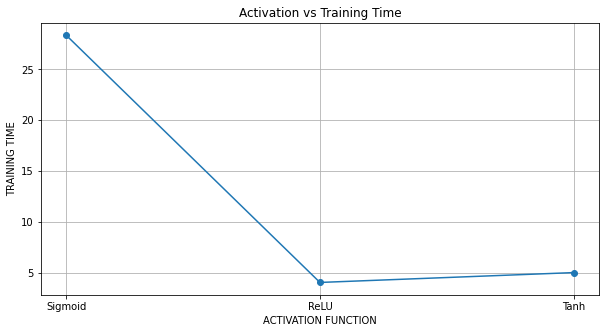

In [30]:
act=["Sigmoid","ReLU","Tanh"]
plt.figure(figsize=(10,5))
plt.plot(act,training_time,marker='o')
plt.xlabel("ACTIVATION FUNCTION")
plt.ylabel("TRAINING TIME")
plt.title("Activation vs Training Time")
plt.grid()
plt.show()

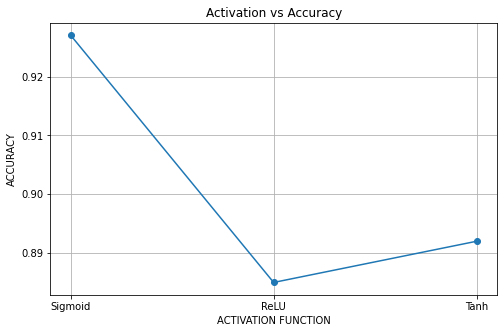

In [33]:
accuracy=[]
accuracy.append(accuracy_score(y_test,sig_pred))
accuracy.append(accuracy_score(y_test,relu_pred))
accuracy.append(accuracy_score(y_test,tanh_pred))
plt.figure(figsize=(8,5))
plt.plot(act,accuracy,marker='o')
plt.xlabel("ACTIVATION FUNCTION")
plt.ylabel("ACCURACY")
plt.title("Activation vs Accuracy")
plt.grid()
plt.show()